In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.font_manager import FontProperties

from dotenv import dotenv_values

from hm3d_utils.plotting import zoom_umap

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Ext_Fig_10" 
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_control.h5ad" 

In [3]:
adata = sc.read_h5ad(SC_ADATA_FP)

In [4]:
sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata, base=2)

In [5]:
def plot_and_save_GE_ctrl_only(adata, genes_to_plot_list, plot_save_dir, save_string_suffix=None, scattersize=15, vmax=None):

    for gene in genes_to_plot_list:

        # Create high-resolution figure and axis
        fig, ax = plt.subplots(figsize=(10, 10)) 

        # Plot with Scanpy onto the given axis
        sc.pl.umap(
            adata[adata.obs.IsControl], 
            color=gene,
            ax=ax,
            show=False,
            size=scattersize,
            vmax=vmax
        )

        # --- Rasterize the scatter plot points ---
        for artist in ax.collections:
            artist.set_rasterized(True)

        # Remove default title, borders, ticks, and labels
        ax.set_title(gene, fontsize=30, fontweight="bold")
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_aspect('equal')

        # Modify the colorbar
        for cax in fig.axes:
            if cax != ax:
                # Shrink the colorbar by modifying its position
                pos = cax.get_position()
                cax.set_position([
                    pos.x0 + 0,      # move right
                    pos.y0 + 0,       # move up
                    pos.width * 20,     # stretch horizontally
                    pos.height * 1#0.75  # shrink vertically
                ])

                # Set label and tick styles
                cax.set_ylabel("log1p(CP10K)", fontsize=30, fontweight='bold', labelpad=10)
                cax.tick_params(labelsize=30)
                for label in cax.get_yticklabels():
                    label.set_fontweight('bold')
                break



        # Save figure
        save_name = f"umap_{gene}_expr_C_only"
        if isinstance(save_string_suffix, str):
            save_name += save_string_suffix

        fig.savefig(
            plot_save_dir + save_name + ".pdf",
            dpi=500,
            format="pdf",
            bbox_inches="tight"
        )


## Tanys

In [6]:
tany = adata[adata.obs.L3_descr.str.contains("Tany")].copy()

In [7]:

#plt.hist(tany.obsm["X_umap"][:, 0], bins=50)

In [8]:

# remove cells outside the main UMAP clusters
tany_mask = (tany.obsm["X_umap"][:, 0] > 12.5) & (tany.obsm["X_umap"][:, 0] < 19) & (
    tany.obsm["X_umap"][:, 1] > 10)


In [9]:
s=60

/beegfs/home/mfeldmann/repos/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


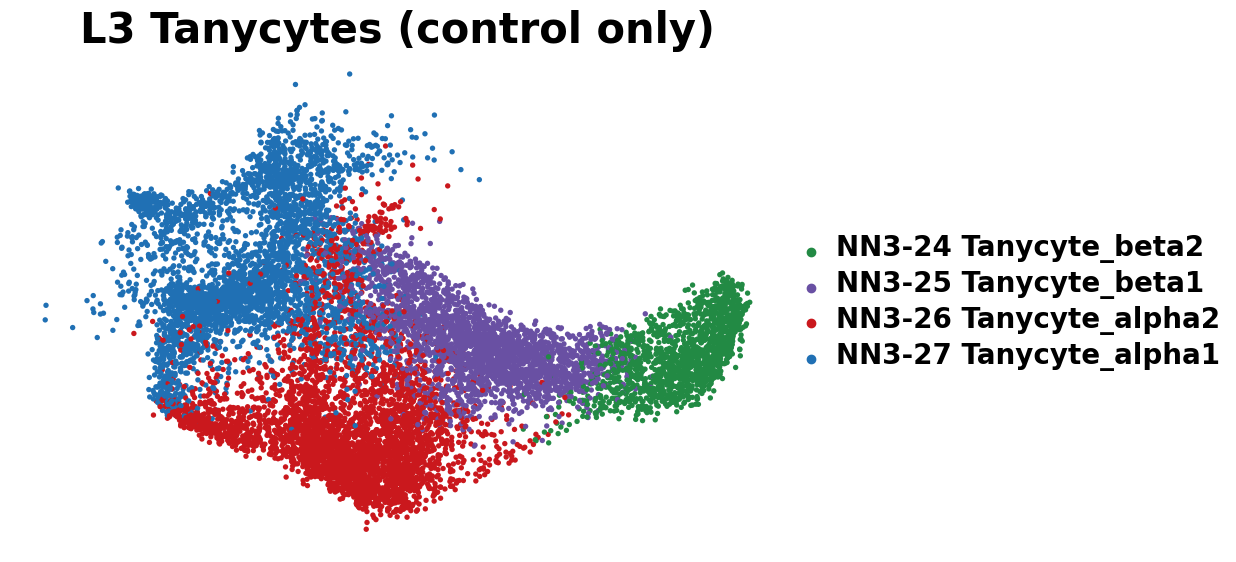

In [10]:
tany_color_dict = {
    'NN3-27 Tanycyte_alpha1': "#2070b4", 
    'NN3-25 Tanycyte_beta1': "#6950a3", 
    'NN3-26 Tanycyte_alpha2': "#ca181d", 
    'NN3-24 Tanycyte_beta2': "#228a44"
    
}

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(10, 10), ) 

# Pass the axis to Scanpy
sc.pl.umap(tany[tany_mask], color="L3_descr", ax=ax, s=s, show=False, palette=tany_color_dict )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("L3 Tanycytes (control only)", fontweight="bold", fontsize=30)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')


# --- Customize legend ---
leg = ax.get_legend()
if leg is not None:
    # Change font size and weight
    for text in leg.get_texts():
        text.set_fontsize(20)
        text.set_fontweight("bold")

fig.canvas.draw()

plt.savefig(OUTDIR / "umap_L3_tany_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 
#plt.show()

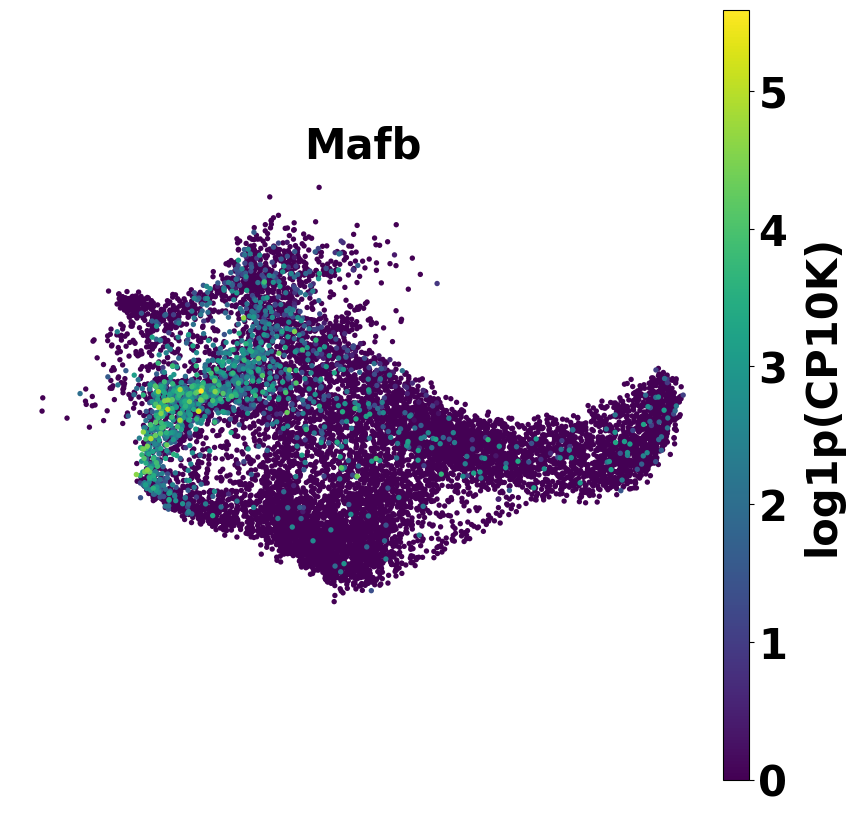

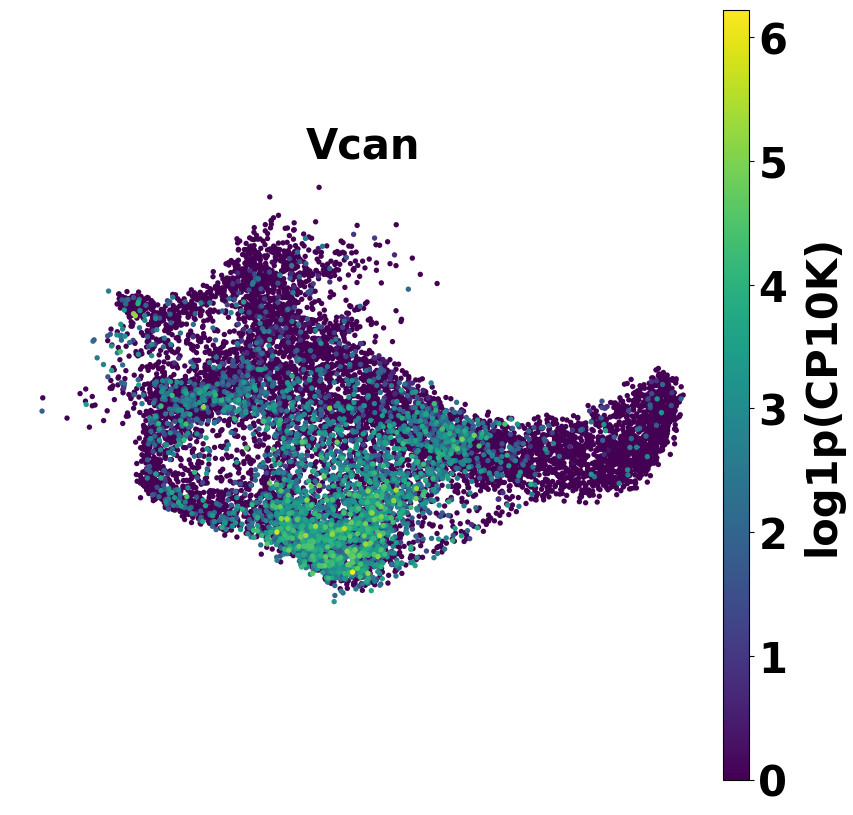

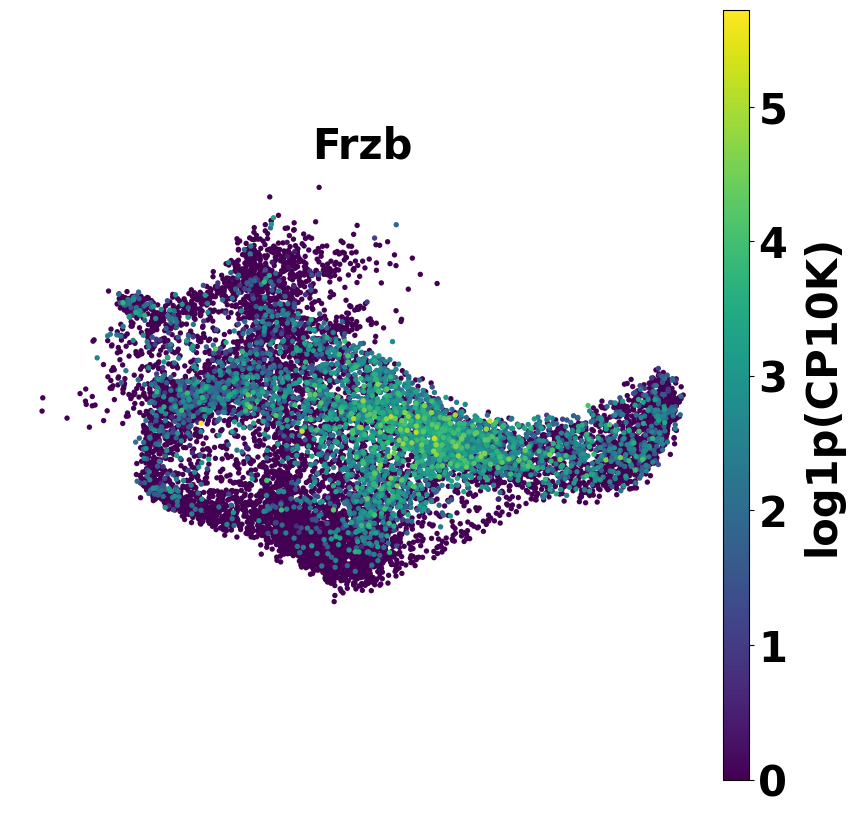

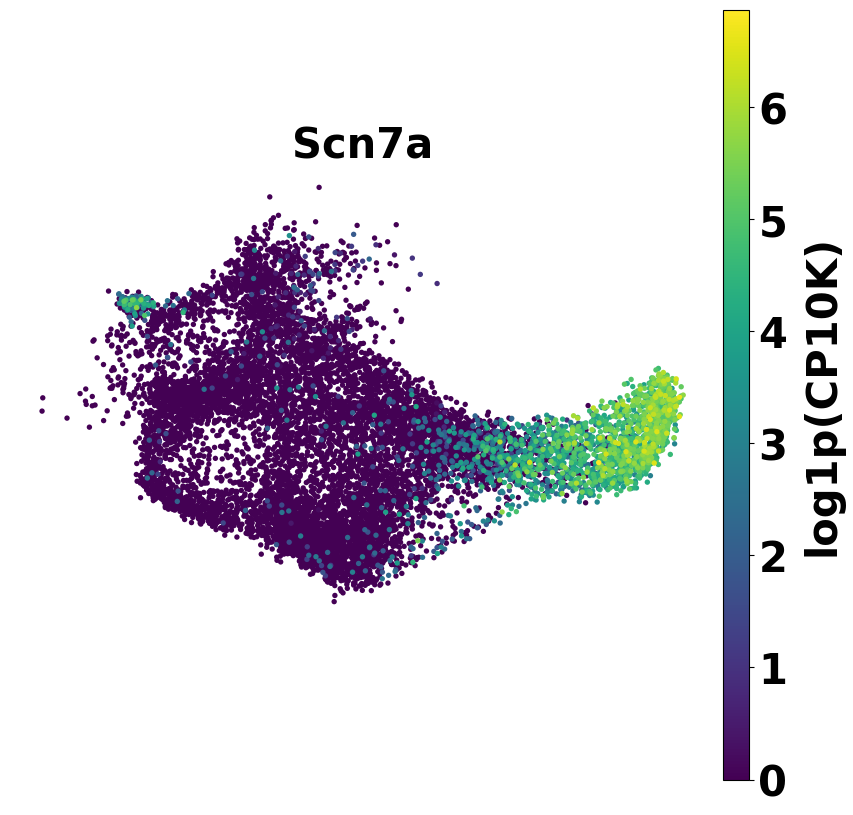

In [11]:

genes_to_plot_list = ["Mafb", "Vcan", "Frzb", "Scn7a"]
save_string_suffix = "_tany_l3"

plot_and_save_GE_ctrl_only(tany[tany_mask], genes_to_plot_list, plot_save_dir = f"{str(OUTDIR)}/", 
save_string_suffix=save_string_suffix, scattersize=s)

## OPC-Oligo

In [12]:
oligo = adata[adata.obs.L1_descr.str.contains("Oligo")].copy()

In [13]:
#plt.hist(oligo[oligo_mask].obsm["X_umap"][:, 0], bins=50)

In [14]:
#remove cells outside the main UMAP clusters
oligo_mask = (oligo.obsm["X_umap"][:, 1] < 10.5) & (oligo.obsm["X_umap"][:, 1] > -5) & (oligo.obsm["X_umap"][:, 0] < 3)

/beegfs/home/mfeldmann/repos/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


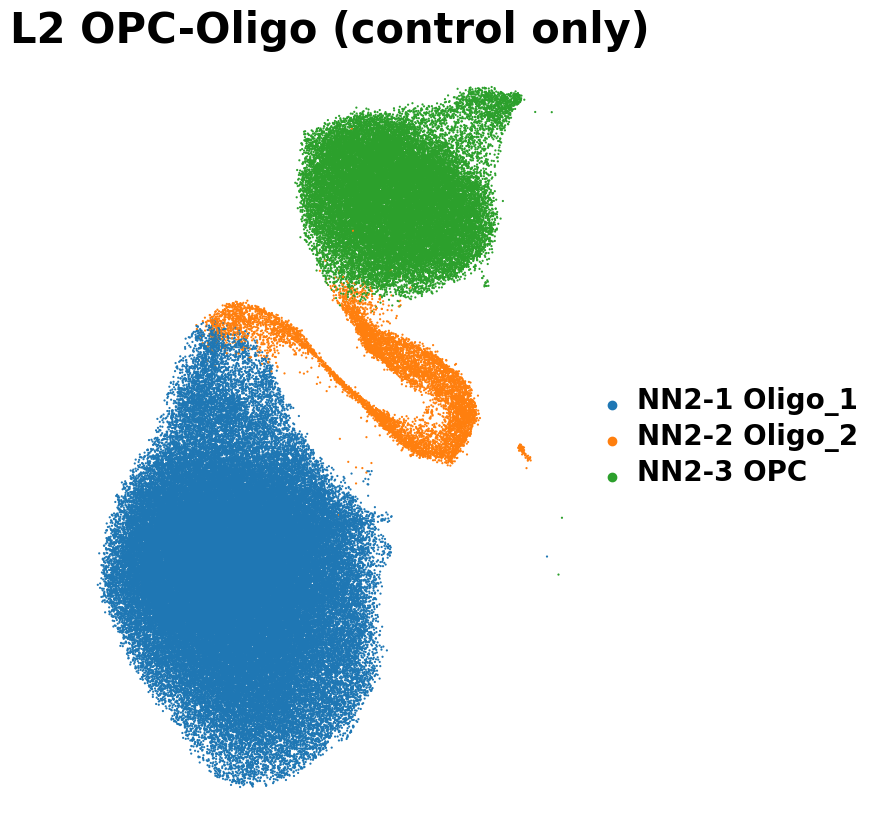

In [15]:
fig, ax = plt.subplots(figsize=(10, 10), ) 
sc.pl.umap(oligo[oligo_mask], color="L2_descr", ax=ax, s=10, show=False,  )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("L2 OPC-Oligo (control only)", fontweight="bold", fontsize=30)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')


# --- Customize legend ---
leg = ax.get_legend()
if leg is not None:
    # Change font size and weight
    for text in leg.get_texts():
        text.set_fontsize(20)
        text.set_fontweight("bold")
    

fig.canvas.draw()

plt.savefig(OUTDIR /  "umap_L2_oligo_opc_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 
#plt.show()

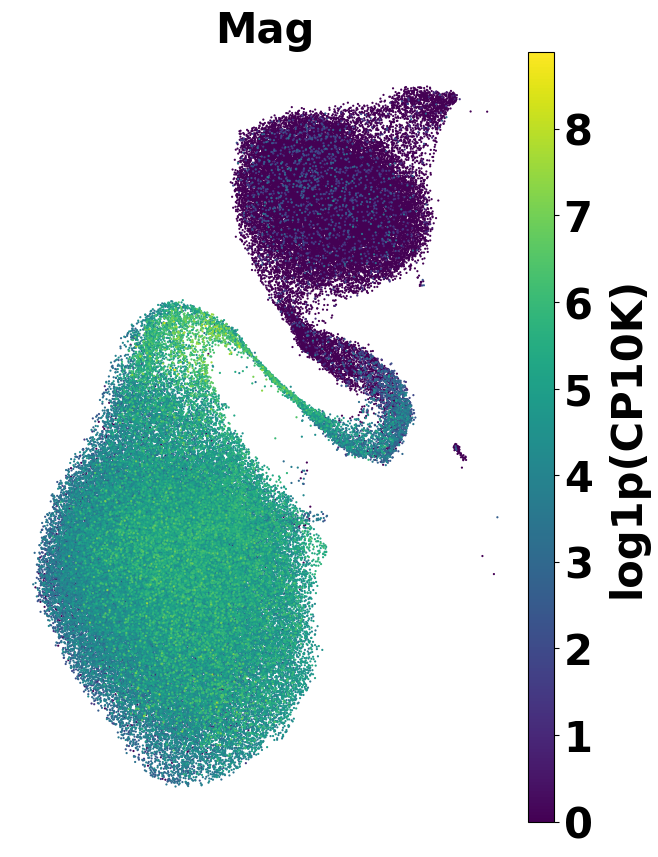

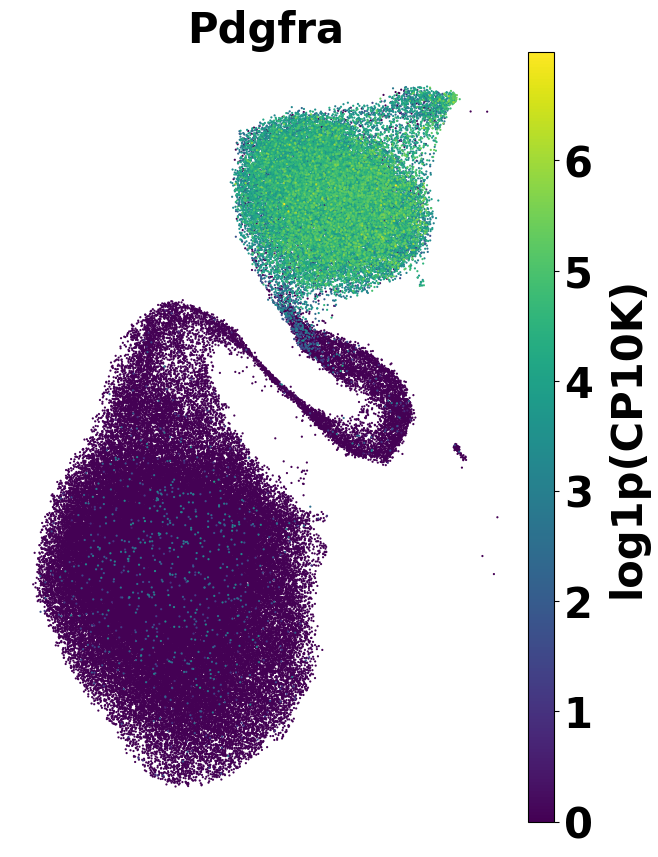

In [16]:

genes_to_plot_list = [ "Mag",#"Mog", 
                "Pdgfra", ]
save_string_suffix = "_oligoopc_l2"

plot_and_save_GE_ctrl_only(oligo[oligo_mask], genes_to_plot_list, plot_save_dir = f"{str(OUTDIR)}/", 
    save_string_suffix=save_string_suffix,scattersize=10)

## MG

In [17]:
mg = adata[adata.obs.L3_descr.str.contains("Micro")].copy()

In [18]:

#plt.hist(mg.obsm["X_umap"][:, 0], bins=50)

In [19]:

#remove cells outside the main UMAP clusters
mg_mask = (mg.obsm["X_umap"][:, 1] > 14) & (
    mg.obsm["X_umap"][:, 0] >5.9)

In [20]:
mg_zoom = mg[mg_mask].copy()

In [21]:
s=100

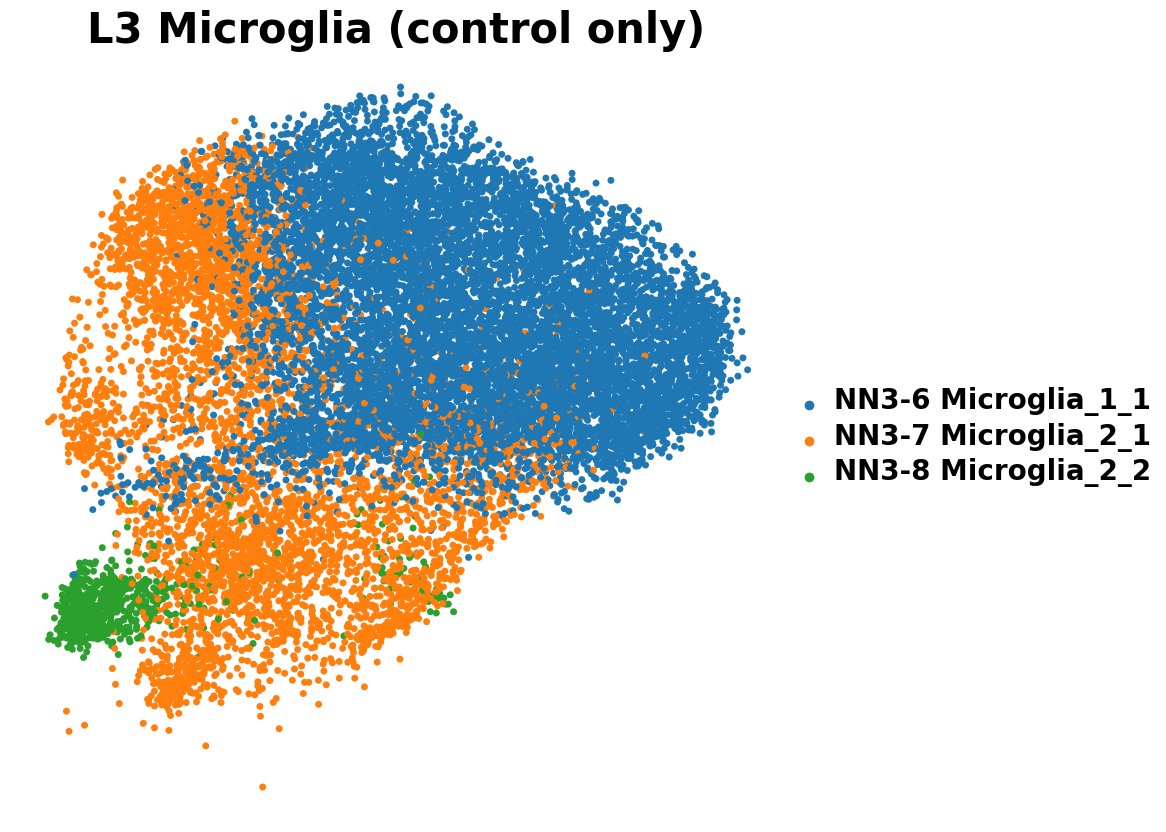

In [22]:

fig, ax = plt.subplots(figsize=(10, 10), ) 
sc.pl.umap(mg_zoom, color="L3_descr", ax=ax, s=s, show=False,  )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("L3 Microglia (control only)", fontweight="bold", fontsize=30)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')


# --- Customize legend ---
leg = ax.get_legend()
if leg is not None:
    # Change font size and weight
    for text in leg.get_texts():
        text.set_fontsize(20)
        text.set_fontweight("bold")


fig.canvas.draw()

plt.savefig(OUTDIR / "umap_L3_microglia_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 
#plt.show()

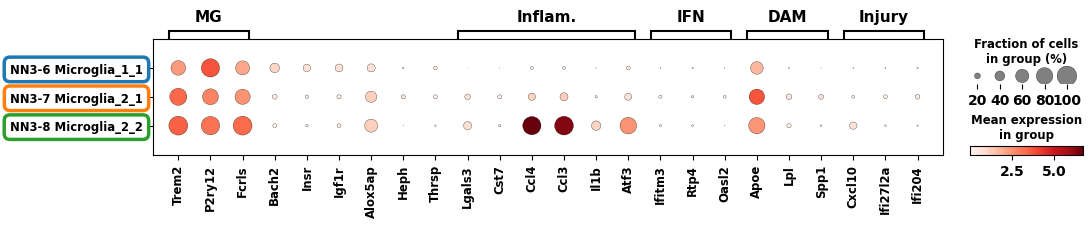

In [30]:

# -------------------
# Define genes and groups
# -------------------
mg_genes = mg_genes = [
    # canonical microglia
    "Trem2", "P2ry12", "Fcrls",

    # 1
    "Bach2", "Insr", "Igf1r", 

    # 2
    "Alox5ap", # increases normal and pathological aging https://www.frontiersin.org/journals/immunology/articles/10.3389/fimmu.2019.01170/full
    "Heph", # hephaestin. is expressed in MG as these guys claim without a ref https://pmc.ncbi.nlm.nih.gov/articles/PMC4943332/
    "Thrsp", # related to imparied cell proliferation https://www.nature.com/articles/srep39258 experimental cerebral malaria

    # OA2 aging cluster (inflammatory)
    "Lgals3", "Cst7", "Ccl4", "Ccl3", "Il1b", "Atf3",
    # OA3 aging cluster (interferon)
    "Ifitm3", "Rtp4", "Oasl2",
    # DAM / demyelination
    "Apoe", "Lpl", "Spp1",
    "Cxcl10", "Ifi27l2a", "Ifi204"
]

# -------------------
# Define group positions
# -------------------
# Note: positions are 0-based index positions in mg_genes
var_group_positions = [
    (0, 2, "MG"),
    #(3, 5, "Metabolic 1"),   # optional extra group for Bach2/Insr/Igf1r
    #(6, 8, "Metabolic 2"),   # optional extra group for Alox5ap/Heph/Thrsp
    (9, 14, "Inflam."),
    (15, 17, "IFN"),
    (18, 20, "DAM"),
    (21, 23, "Injury")
]

# -------------------
# Compute figure size
# -------------------
total_height = 0.5 * len(mg.obs.L3_descr.unique())

# -------------------
# Create DotPlot
# -------------------
dotplot_obj = sc.pl.DotPlot(
    mg[mg.obs.IsControl],
    var_names=mg_genes,
    groupby="L3_descr",
    var_group_positions=[(start, end) for start, end, _ in var_group_positions],
    var_group_labels=[label for _, _, label in var_group_positions],
    var_group_rotation=0,
    figsize=(12, total_height),
    cmap="Reds",
    #standard_scale="var",  # optional normalization per gene
)

# Build the figure
dotplot_obj.make_figure()

# -------------------
# Customize axes and labels
# -------------------
ax = dotplot_obj.ax_dict['mainplot_ax']

# Make gene and group labels bold and add colored boxes
for i, label in enumerate(ax.get_yticklabels()):
    label.set_fontweight('bold')
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

# Color boxes around y-tick labels by cluster color
if "L3_descr_colors" in mg_zoom.uns:
    colors = mg_zoom.uns["L3_descr_colors"]
    for i, label in enumerate(ax.get_yticklabels()):
        color = colors[i % len(colors)]
        label.set_bbox(dict(facecolor="white", edgecolor=color,
                            boxstyle='round,pad=0.5', linewidth=2.5))

# -------------------
# Colorbar and legends
# -------------------
cbar_ax = dotplot_obj.fig.axes[-1]
for txt_obj in cbar_ax.texts + cbar_ax.get_yticklabels() + cbar_ax.get_xticklabels():
    txt_obj.set_fontweight('bold')
    txt_obj.set_fontsize(10)

if cbar_ax.get_ylabel():
    cbar_ax.set_ylabel(cbar_ax.get_ylabel(), fontweight='bold')
if cbar_ax.get_xlabel():
    cbar_ax.set_xlabel(cbar_ax.get_xlabel(), fontweight='bold')

for text in cbar_ax.texts:
    text.set_fontweight('bold')

size_legend_ax = dotplot_obj.ax_dict['size_legend_ax']
for tick in size_legend_ax.get_xticklabels() + size_legend_ax.get_yticklabels():
    tick.set_fontweight('bold')

# Make "expression"/"fraction" text bold
for text_obj in dotplot_obj.fig.findobj(match=plt.Text):
    txt = text_obj.get_text().lower()
    if "expression" in txt or "fraction" in txt:
        text_obj.set_fontweight('bold')
    if txt in ["20", "40", "60", "80", "100"]:
        text_obj.set_fontsize(10)

# Make var_group_labels (like "MG", "Inflam.") bold
for ax_name, ax in dotplot_obj.ax_dict.items():
    if "group" in ax_name:  # these axes hold the var_group labels
        for text_obj in ax.texts:
            text_obj.set_fontweight('bold')
            text_obj.set_fontsize(11)  # optional, adjust for clarity

size_ax = dotplot_obj.ax_dict["size_legend_ax"]

pos = size_ax.get_position()
size_ax.set_position([
    pos.x0,
    pos.y0 + 0.15,   # move down
    pos.width,
    pos.height
])

# -------------------
# Save and show
# -------------------
plt.savefig(OUTDIR / "dotplot_L3_MG.pdf", dpi=300, format="pdf", bbox_inches="tight")
plt.show()